# Bagian D: Regresi Linier dengan Python

**Fundamen Sains Data: Pengantar Machine Learning, Supervised Learning dan Regresi Linier**
Program Studi Informatika, Program Sarjana, Universitas Islam Indonesia

Bagian ini mempraktikkan materi *supervised learning* dan regresi linier. Kita akan:

1. menghitung garis regresi secara manual dengan NumPy pada data lima mahasiswa,
2. melatih model regresi linier dengan scikit-learn pada data yang lebih besar,
3. mengevaluasi model dengan MAE, MSE, RMSE, dan $R^2$ pada data uji,
4. memakai model untuk prediksi dan memeriksa residualnya,
5. melatih model yang sama dengan *gradient descent* sederhana.

Jalankan cell secara berurutan dari atas ke bawah, atau pilih **Runtime > Restart session and run all**.

## D.1 Mengimpor Library

In [1]:
%matplotlib inline
import numpy as np                      # komputasi numerik dan array
import pandas as pd                     # tabel data (DataFrame)
import matplotlib.pyplot as plt         # visualisasi

from sklearn.model_selection import train_test_split   # membagi data latih dan uji
from sklearn.linear_model import LinearRegression      # model regresi linier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Library berhasil diimpor")

Library berhasil diimpor


## D.2 Regresi Linier Manual dengan NumPy

Kita mulai dari *dataset* lima mahasiswa yang sama dengan modul. Koefisien OLS dihitung dengan rumus berikut.

$$b_1 = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^{n}(x_i-\bar{x})^2} \tag{1}$$

**Keterangan:**

- $b_1$ = kemiringan garis OLS
- $x_i$ = jam belajar mahasiswa ke-$i$
- $y_i$ = nilai ujian mahasiswa ke-$i$
- $\bar{x}$ = rata-rata jam belajar
- $\bar{y}$ = rata-rata nilai ujian
- $n$ = jumlah observasi
- $\sum$ = penjumlahan atas seluruh observasi

$$b_0 = \bar{y} - b_1\bar{x} \tag{2}$$

**Keterangan:**

- $b_0$ = intersep garis OLS
- $\bar{y}$ = rata-rata nilai ujian
- $b_1$ = kemiringan dari Persamaan 1
- $\bar{x}$ = rata-rata jam belajar

In [2]:
# data lima mahasiswa
x = np.array([1, 2, 3, 4, 5])          # jam belajar
y = np.array([50, 55, 65, 70, 80])     # nilai ujian

x_bar = x.mean()
y_bar = y.mean()
print("Rata-rata x:", x_bar, "| rata-rata y:", y_bar)

# Persamaan 1 dan 2
b1 = np.sum((x - x_bar) * (y - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print(f"Kemiringan b1 = {b1:.2f}")
print(f"Intersep   b0 = {b0:.2f}")

Rata-rata x: 3.0 | rata-rata y: 64.0
Kemiringan b1 = 7.50
Intersep   b0 = 41.50


Hasilnya sama dengan perhitungan tangan di modul: $b_1 = 7{,}5$ dan $b_0 = 41{,}5$. Selanjutnya kita hitung prediksi, residual, *sum of squared residuals* (SSR), dan MSE.

In [3]:
y_pred = b0 + b1 * x          # prediksi untuk setiap mahasiswa
residual = y - y_pred         # aktual dikurangi prediksi

tabel = pd.DataFrame({"jam": x, "aktual": y, "prediksi": y_pred, "residual": residual})
print(tabel)

ssr = np.sum(residual ** 2)
mse = np.mean(residual ** 2)
print(f"\nSSR = {ssr:.2f}")
print(f"MSE = {mse:.2f}")

   jam  aktual  prediksi  residual
0    1      50      49.0       1.0
1    2      55      56.5      -1.5
2    3      65      64.0       1.0
3    4      70      71.5      -1.5
4    5      80      79.0       1.0

SSR = 7.50
MSE = 1.50


## D.3 Menyiapkan Dataset yang Lebih Besar

Lima observasi terlalu sedikit untuk dibagi menjadi data latih dan data uji. Kita membuat data simulasi 100 mahasiswa dengan pola yang mirip: nilai naik sekitar 7 poin per jam belajar, ditambah variasi acak. `random_state` dan *seed* yang tetap membuat hasil Anda sama dengan hasil di modul.

In [4]:
rng = np.random.default_rng(42)       # seed tetap agar hasil dapat diulang

jam = rng.uniform(0.5, 8, 100).round(1)                    # jam belajar 0,5 sampai 8 jam
nilai = (40 + 7 * jam + rng.normal(0, 5, 100)).clip(0, 100).round(1)

df = pd.DataFrame({"jam_belajar": jam, "nilai_ujian": nilai})
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (100, 2)


,jam_belajar,nilai_ujian
0,6.3,86.1
1,3.8,62.1
2,6.9,86.4
3,5.7,86.4
4,1.2,46.6


In [5]:
df.describe().round(2)

,jam_belajar,nilai_ujian
count,100.00,100.00
mean,4.15,68.99
std,2.05,15.23
min,0.60,42.80
25%,2.28,55.92
50%,4.00,68.65
75%,5.82,82.70
max,7.80,100.00


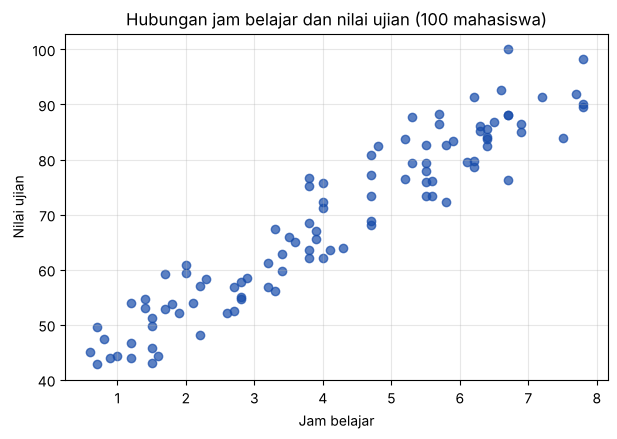

In [6]:
plt.figure(figsize=(7, 4.5))
plt.scatter(df["jam_belajar"], df["nilai_ujian"], color="#174CAA", alpha=0.7)
plt.xlabel("Jam belajar")
plt.ylabel("Nilai ujian")
plt.title("Hubungan jam belajar dan nilai ujian (100 mahasiswa)")
plt.grid(alpha=0.3)
plt.show()

Grafik memperlihatkan hubungan positif yang kira-kira linier, sehingga regresi linier merupakan pilihan yang masuk akal.

## D.4 Membagi Data Latih dan Data Uji

Fitur `X` harus berbentuk tabel dua dimensi (baris, kolom), sedangkan target `y` berbentuk satu dimensi. Karena itu fitur diambil dengan kurung siku ganda `df[["jam_belajar"]]`.

In [7]:
X = df[["jam_belajar"]]     # fitur: DataFrame 2 dimensi
y = df["nilai_ujian"]       # target: Series 1 dimensi

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Data latih:", X_train.shape, "| data uji:", X_test.shape)

Data latih: (80, 1) | data uji: (20, 1)


## D.5 Melatih Model Regresi Linier

`LinearRegression` menghitung koefisien OLS secara langsung. Metode `fit()` hanya menerima data latih; data uji disimpan untuk evaluasi.

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intersep  (b0): {model.intercept_:.2f}")
print(f"Kemiringan (b1): {model.coef_[0]:.2f}")

Intersep  (b0): 39.69
Kemiringan (b1): 7.15


Model mempelajari bahwa setiap tambahan satu jam belajar menaikkan prediksi nilai sekitar 7 poin, dekat dengan pola yang kita pakai saat membuat data.

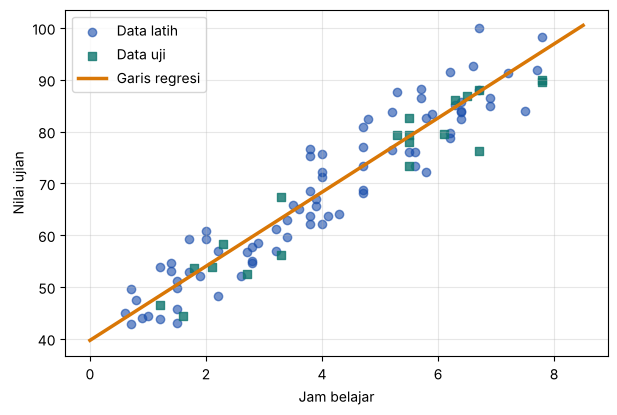

In [9]:
garis_x = np.linspace(0, 8.5, 100).reshape(-1, 1)
garis_y = model.predict(pd.DataFrame(garis_x, columns=["jam_belajar"]))

plt.figure(figsize=(7, 4.5))
plt.scatter(X_train, y_train, color="#174CAA", alpha=0.6, label="Data latih")
plt.scatter(X_test, y_test, color="#0F766E", marker="s", alpha=0.8, label="Data uji")
plt.plot(garis_x, garis_y, color="#D97706", linewidth=2.5, label="Garis regresi")
plt.xlabel("Jam belajar")
plt.ylabel("Nilai ujian")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## D.6 Mengevaluasi Model

Kita menghitung metrik pada data latih dan data uji. Kinerja pada data uji adalah ukuran generalisasi yang sebenarnya.

In [10]:
def evaluasi(y_asli, y_prediksi):
    """Mengembalikan MAE, MSE, RMSE, dan R2 dalam bentuk dictionary."""
    mse = mean_squared_error(y_asli, y_prediksi)
    return {"MAE": float(mean_absolute_error(y_asli, y_prediksi)),
            "MSE": float(mse),
            "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_asli, y_prediksi))}

hasil = pd.DataFrame({
    "Data latih": evaluasi(y_train, model.predict(X_train)),
    "Data uji": evaluasi(y_test, model.predict(X_test))}).round(3)
hasil

,Data latih,Data uji
MAE,4.062,3.593
MSE,24.369,21.356
RMSE,4.936,4.621
R2,0.894,0.906


RMSE berada dalam satuan poin, sehingga mudah ditafsirkan: rata-rata prediksi meleset sekitar 5 poin. Nilai $R^2$ pada data uji yang mendekati nilai pada data latih menunjukkan model tidak sekadar menghafal data latih.

## D.7 Prediksi Data Baru dan Ekstrapolasi

Data latih mencakup 0,5 sampai 8 jam belajar. Prediksi di dalam rentang itu adalah interpolasi; di luar rentang adalah ekstrapolasi.

In [11]:
data_baru = pd.DataFrame({"jam_belajar": [2.5, 6, 12]})
data_baru["prediksi_nilai"] = model.predict(data_baru).round(1)
data_baru["jenis"] = np.where(data_baru["jam_belajar"].between(0.5, 8), "interpolasi", "ekstrapolasi")
data_baru

,jam_belajar,prediksi_nilai,jenis
0,2.5,57.6,interpolasi
1,6.0,82.6,interpolasi
2,12.0,125.5,ekstrapolasi


Prediksi untuk 12 jam melebihi nilai maksimum 100. Model hanya memperpanjang garis lurus, sehingga prediksi di luar rentang data perlu diperlakukan dengan hati-hati.

## D.8 Memeriksa Residual

Plot residual terhadap nilai prediksi membantu memeriksa apakah pola linier sudah tertangkap. Residual yang tersebar acak di sekitar nol tanpa pola melengkung menandakan model linier sudah memadai.

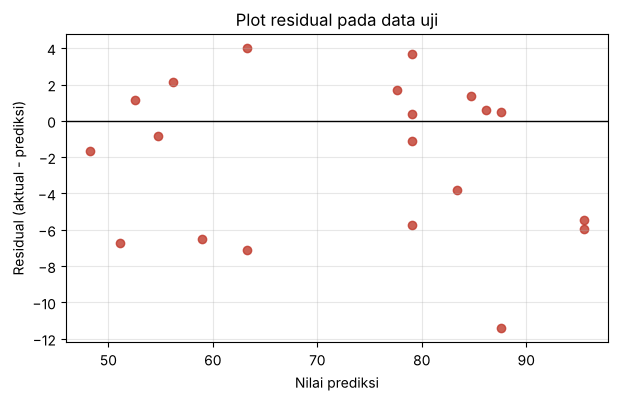

In [12]:
pred_test = model.predict(X_test)
res_test = y_test - pred_test

plt.figure(figsize=(7, 4))
plt.scatter(pred_test, res_test, color="#C0392B", alpha=0.8)
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Nilai prediksi")
plt.ylabel("Residual (aktual - prediksi)")
plt.title("Plot residual pada data uji")
plt.grid(alpha=0.3)
plt.show()

## D.9 Melatih Model dengan Gradient Descent

`LinearRegression` memakai solusi langsung OLS. Sebagai perbandingan, kita melatih model yang sama secara iteratif: mulai dari koefisien nol, hitung gradien MSE, lalu geser koefisien sedikit demi sedikit ke arah yang menurunkan MSE. *Learning rate* menentukan besar setiap langkah.

In [13]:
x_tr = X_train["jam_belajar"].to_numpy()
y_tr = y_train.to_numpy()

b0_gd, b1_gd = 0.0, 0.0       # koefisien awal
learning_rate = 0.02
riwayat_mse = []

for epoch in range(5000):
    pred = b0_gd + b1_gd * x_tr
    error = y_tr - pred
    riwayat_mse.append(np.mean(error ** 2))
    # gradien MSE terhadap b0 dan b1
    grad_b0 = -2 * np.mean(error)
    grad_b1 = -2 * np.mean(x_tr * error)
    b0_gd -= learning_rate * grad_b0
    b1_gd -= learning_rate * grad_b1

print(f"Gradient descent: b0 = {b0_gd:.2f}, b1 = {b1_gd:.2f}")
print(f"LinearRegression: b0 = {model.intercept_:.2f}, b1 = {model.coef_[0]:.2f}")

Gradient descent: b0 = 39.69, b1 = 7.15
LinearRegression: b0 = 39.69, b1 = 7.15


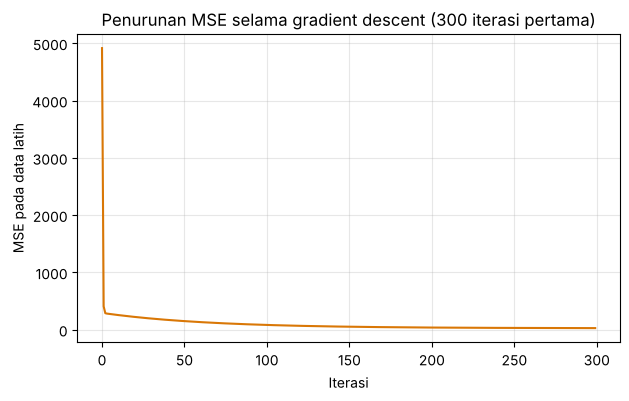

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(riwayat_mse[:300], color="#D97706")
plt.xlabel("Iterasi")
plt.ylabel("MSE pada data latih")
plt.title("Penurunan MSE selama gradient descent (300 iterasi pertama)")
plt.grid(alpha=0.3)
plt.show()

Kedua cara menghasilkan koefisien yang hampir sama. Untuk regresi linier, solusi langsung lebih cepat; *gradient descent* menjadi penting pada model yang tidak memiliki rumus langsung.

## Penutup

Latihan untuk bagian ini beserta penyelesaiannya tersedia di notebook `latihan-akhir.ipynb` pada folder yang sama.